# LAPTOP PRICE PREDICTION

## 1. Project Overview

This project aims to build a machine learning model to predict laptop prices based on their specifications and hardware features.

## 2. Business Question

**Can laptop prices be predicted using their specifications and hardware features?**

## 3. Objectives

- Identify the features that influence laptop prices.
- Build a regression model to predict laptop prices.
- Evaluate model performance using appropriate regression metrics.
- Compare actual laptop prices with predicted prices.

## 4. Dataset Description

The dataset contains laptop specifications and their corresponding prices. Features include brand, processor, RAM, storage, GPU, operating system, screen resolution, screen size, weight, and price.

## 5. Modelling Approach

The project will follow these steps:

1. Load the cleaned dataset.
2. Select the target variable and predictor features.
3. Split the data into training and testing sets.
4. Establish a baseline model.
5. Train a Linear Regression model.
6. Evaluate model performance using MAE, RMSE, and \(R^2\).
7. Interpret the results and identify possible improvements.


In [36]:
# import necessary dependancies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from category_encoders import OneHotEncoder
from sklearn.linear_model import LinearRegression,LassoCV,RidgeCV
from sklearn.metrics import root_mean_squared_error,mean_absolute_error,r2_score
from sklearn.pipeline import make_pipeline

In [37]:
# get data
filepath="../data/global-laptop-selling-dataset/modelling_clean_global_laptop_selling_data.csv"
laptop_df =pd.read_csv(filepath,index_col="laptop_ID")
laptop_df.head()

,Company,Product,TypeName,Ram,Price_euros,PixelsMP,DisplayFeatures,CpuBrand,CpuModel,ClockSpeed,SSDCapacityGB,HDDCapacityGB,FlashStorageGB,HybridStorageGB,WeightKg,GpuBrand,GpuModel,OsFamily
laptop_ID,,,,,,,,,,,,,,,,,,
1,Apple,MacBook Pro,Ultrabook,8,1339.69,4.10,IPS Panel Retina Display,Intel,Core i5,2.3,128.0,0.0,0.0,0.0,1.37,Intel,Iris Plus Graphics 640,macOS
2,Apple,Macbook Air,Ultrabook,8,898.94,1.30,NaN,Intel,Core i5,1.8,0.0,0.0,128.0,0.0,1.34,Intel,HD Graphics 6000,macOS
3,HP,250 G6,Notebook,8,575.00,2.07,Full HD,Intel,Core i5 7200U,2.5,256.0,0.0,0.0,0.0,1.86,Intel,HD Graphics 620,No OS
4,Apple,MacBook Pro,Ultrabook,16,2537.45,5.18,IPS Panel Retina Display,Intel,Core i7,2.7,512.0,0.0,0.0,0.0,1.83,AMD,Radeon Pro 455,macOS
5,Apple,MacBook Pro,Ultrabook,8,1803.60,4.10,IPS Panel Retina Display,Intel,Core i5,3.1,256.0,0.0,0.0,0.0,1.37,Intel,Iris Plus Graphics 650,macOS


### Separate target and features

In [38]:

target ="Price_euros"
features=[col for col in laptop_df.columns if col not in target] 

X=laptop_df[features]
y=laptop_df[target]

### Split data into train and testing

In [39]:

X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=0.2,random_state=42)

print(f"X_train shape {X_train.shape}")
print(f"X_test shape {X_test.shape}")
print(f"y_train shape {y_train.shape}")
print(f"y_test shape  {y_test.shape}")


X_train shape (1042, 17)
X_test shape (261, 17)
y_train shape (1042,)
y_test shape  (261,)


### Baseline model

In [40]:
y_mean=y_train.mean()

y_pred_baseline_train =[y_mean] *len(y_train)
y_pred_baseline_test=[y_mean]*len(y_test)

RMSE_baseline_train=root_mean_squared_error(y_train,y_pred_baseline_train)
RMSE_baseline_test=root_mean_squared_error(y_test,y_pred_baseline_test)

print(f"Baseline Train RMSE : €{RMSE_baseline_train:,.2f}")
print(f"Baseline Test RMSE: €{RMSE_baseline_test:,.2f}")

Baseline Train RMSE : €695.13
Baseline Test RMSE: €713.07


### Calculate RMSE

In [41]:
def get_rmse(model,x,y):
    y_pred=model.predict(x)
    rmse=root_mean_squared_error(y,y_pred)
    return rmse
    


### Linear Regression

In [44]:
linear_model =make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    LinearRegression()
)

linear_model.fit(X_train,y_train)

linear_train_rmse=get_rmse(linear_model,X_train,y_train)
linear_test_rmse=get_rmse(linear_model,X_test,y_test)

print(f"linear train RMSE : €{linear_train_rmse:,.2f}")
print(f"Linear Test RMSE: €{linear_test_rmse:,.2f}")



linear train RMSE : €91.26
Linear Test RMSE: €314.51


### Ridge Regression

In [45]:
ridge_model =make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    RidgeCV(alphas=np.logspace(-2,4,100))
    
)

ridge_model.fit(X_train,y_train)

ridge_train_rmse=get_rmse(ridge_model,X_train,y_train)
ridge_test_rmse=get_rmse(ridge_model,X_test,y_test)

print(f"Ridge train RMSE : €{ridge_train_rmse:,.2f}")
print(f"Ridge Test RMSE: €{ridge_test_rmse:,.2f}")

Ridge train RMSE : €117.48
Ridge Test RMSE: €263.22


### Lasso Regression

In [47]:
lasso_model=make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    LassoCV(alphas=np.logspace(-4,2,100),max_iter=10000)
)

lasso_model.fit(X_train,y_train)

lasso_train_rmse=get_rmse(lasso_model,X_train,y_train)
lasso_test_rmse=get_rmse(lasso_model,X_test,y_test)

print(f"Lasso train RMSE : €{lasso_train_rmse:,.2f}")
print(f"Lasso Test RMSE: €{lasso_test_rmse:,.2f}")

Lasso train RMSE : €132.03
Lasso Test RMSE: €241.89


In [50]:
comparison_table={
    "Model":["Baseline","Linear Regrssion","Ridge (cv tuned)","Lasso (cv tuned)"],
    "train_RMSE":[RMSE_baseline_train,linear_train_rmse,ridge_train_rmse,lasso_train_rmse],
    "test_RMSE":[RMSE_baseline_test,linear_test_rmse,ridge_test_rmse,lasso_test_rmse]
}

comparison_df=pd.DataFrame(comparison_table)
comparison_df["gap"]=comparison_df["test_RMSE"]-comparison_df["train_RMSE"]
comparison_df.set_index("Model")

,train_RMSE,test_RMSE,gap
Model,,,
Baseline,695.125117,713.068877,17.943759
Linear Regrssion,91.260874,314.506091,223.245216
Ridge (cv tuned),117.475370,263.223568,145.748198
Lasso (cv tuned),132.033663,241.894241,109.860578


**Model Evaluation and Selection**

Lasso Regression performed best among the evaluated regression models, achieving the lowest test RMSE of 241.89 and a train–test RMSE gap of 109.86. Compared with Linear Regression and Ridge Regression, Lasso demonstrated better test-set performance and a smaller generalization gap. This suggests that regularization improved the model's ability to predict laptop prices on unseen data. 

## visualize perfomance

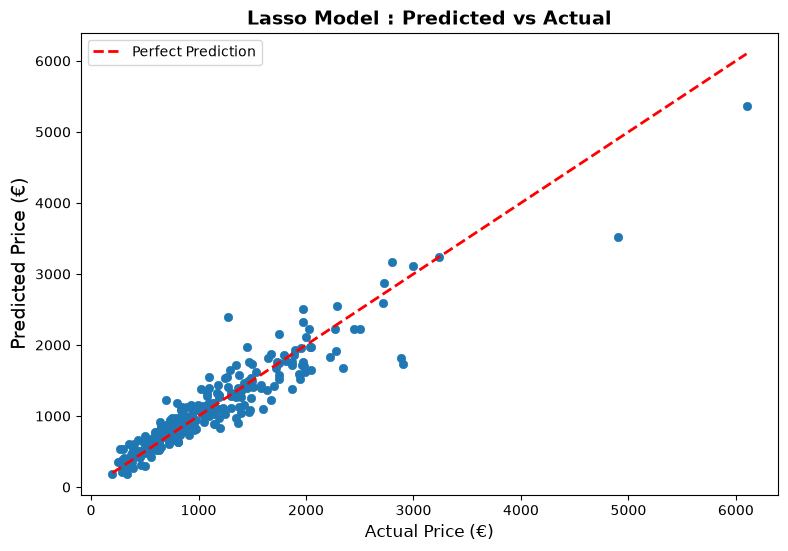

In [60]:
y_pred_lasso=lasso_model.predict(X_test)
fig,ax=plt.subplots(figsize=(9,6))
ax.scatter(y_test,y_pred_lasso,linewidths=0.5)
ideal_line=np.linspace(y_test.min(),y_test.max(),100)
ax.plot(ideal_line,ideal_line,color="red",linestyle="--",linewidth=2,label="Perfect Prediction")
ax.set_xlabel("Actual Price (€)",fontsize=12)
ax.set_ylabel("Predicted Price (€)",fontsize=14)
ax.set_title("Lasso Model : Predicted vs Actual",fontweight="bold",fontsize=14)
ax.legend()

**Spread grows with price**. Below €1,000, the predictions are relatively close to actual prices, while above €1,500, the errors become more dispersed. 

### Redidual analysis

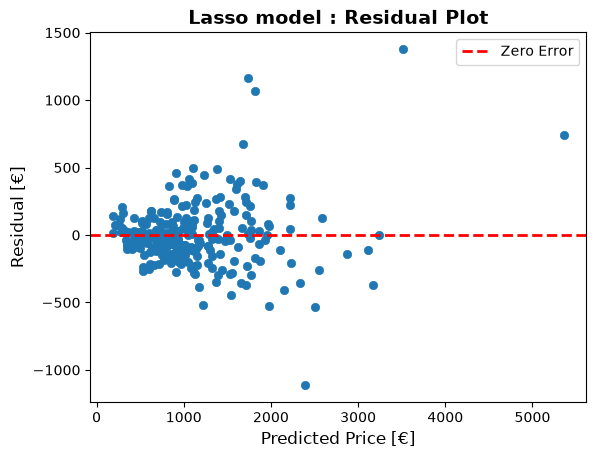

In [61]:
residual=y_test-y_pred_lasso
fig,ax=plt.subplots()
ax.scatter(y_pred_lasso,residual,linewidths=0.5)
ax.axhline(y=0,color="red",linewidth=2,linestyle="--",label="Zero Error")
ax.set_xlabel("Predicted Price [€]",fontsize=12)
ax.set_ylabel("Residual [€]",fontsize=12)
ax.set_title("Lasso model : Residual Plot",fontsize=14,fontweight="bold")
ax.legend()
plt.show()
